# 02 · Calidad de datos: primeras reglas (R2 · Hito 2)
**Proyecto semestral · Sala de crisis COVID-19 · Gestión de Datos IN1232C · 2026-2**

Requiere haber ejecutado `01_ingesta` (lee la capa limpia en Parquet).

1. **Homologación de países**: el mismo país aparece con varios nombres (`Mainland China`, `Korea, South`…). Se construye una tabla nombre original → país UID → ISO3.
2. **Serie país × día** con casos y fallecidos nuevos (diferencia de acumulados).
3. **Reglas ejecutables** de las seis dimensiones (completitud, unicidad, validez, consistencia, exactitud, oportunidad), con métrica, umbral y estado, en una función `evaluar_calidad()` que se corre en cada carga.
4. **Cuantificación por país** de los problemas que pide el enunciado.

> Primera versión para el Hito 2. El índice de calidad por país y las decisiones finales (corregir, marcar o excluir) se completan en la siguiente iteración.

## 1 · Configuración y carga

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROYECTO = Path('/content/drive/MyDrive/proyecto-gestion-datos-2026')
else:
    PROYECTO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CLEAN = PROYECTO / 'data' / 'clean'
assert (CLEAN / 'daily_reports.parquet').exists(), 'Primero ejecuta 01_ingesta'

pd.set_option('display.max_columns', None)
diario = pd.read_parquet(CLEAN / 'daily_reports.parquet')
uid = pd.read_parquet(CLEAN / 'uid_lookup.parquet')
print(f'{len(diario):,} filas · {diario["fecha_reporte"].min().date()} a {diario["fecha_reporte"].max().date()}')

4,287,473 filas · 2020-01-22 a 2023-03-09


## 2 · Homologación de nombres de país
Regla: el nombre «oficial» es el de la tabla UID (fila de nivel país, sin provincia). Los nombres antiguos se mapean a mano; los **territorios de ultramar** que en marzo-2020 se informaban como «país» (Aruba, Guadeloupe, Guam…) pasan a su país soberano y conservan su nombre como provincia, igual que hace JHU desde el 22-mar-2020.

In [2]:
HOMOLOGAR_PAIS = {
    'Mainland China': 'China', 'Hong Kong': 'China', 'Hong Kong SAR': 'China', 'Macau': 'China', 'Macao SAR': 'China',
    'Taiwan': 'Taiwan*', 'Taipei and environs': 'Taiwan*',
    'South Korea': 'Korea, South', 'Republic of Korea': 'Korea, South',
    'Iran (Islamic Republic of)': 'Iran', 'Czech Republic': 'Czechia', 'Ivory Coast': "Cote d'Ivoire",
    'North Ireland': 'United Kingdom', 'Republic of Ireland': 'Ireland', 'Republic of Moldova': 'Moldova',
    'Republic of the Congo': 'Congo (Brazzaville)', 'Russian Federation': 'Russia', 'Viet Nam': 'Vietnam',
    'Vatican City': 'Holy See', 'Palestine': 'West Bank and Gaza', 'occupied Palestinian territory': 'West Bank and Gaza',
    'Bahamas, The': 'Bahamas', 'The Bahamas': 'Bahamas', 'Gambia, The': 'Gambia', 'The Gambia': 'Gambia',
    'East Timor': 'Timor-Leste', 'Cape Verde': 'Cabo Verde',
    'Cruise Ship': 'Diamond Princess', 'Others': 'Diamond Princess',     # en feb-mar 2020 'Others' era el crucero
    # territorios de ultramar informados como país en mar-2020
    'Aruba': 'Netherlands', 'Curacao': 'Netherlands',
    'Cayman Islands': 'United Kingdom', 'Channel Islands': 'United Kingdom', 'Gibraltar': 'United Kingdom',
    'Guernsey': 'United Kingdom', 'Jersey': 'United Kingdom',
    'Faroe Islands': 'Denmark', 'Greenland': 'Denmark',
    'French Guiana': 'France', 'Guadeloupe': 'France', 'Martinique': 'France', 'Mayotte': 'France',
    'Reunion': 'France', 'Saint Barthelemy': 'France', 'Saint Martin': 'France', 'St. Martin': 'France',
    'Guam': 'US', 'Puerto Rico': 'US',
}
# Entidades que no son países: se conservan pero se marcan (se excluyen de rankings y tasas)
ENTIDADES_ESPECIALES = {'Diamond Princess', 'MS Zaandam', 'Summer Olympics 2020', 'Winter Olympics 2022', 'Antarctica'}

paises_uid = uid[uid['province_state'].isna() & uid['admin2'].isna()][['country_region', 'iso3', 'uid', 'population']]
paises_uid = paises_uid.rename(columns={'country_region': 'pais', 'uid': 'uid_pais', 'population': 'poblacion_pais'})

nombres = pd.DataFrame({'country_region': diario['country_region'].cat.categories})
nombres['pais'] = nombres['country_region'].map(HOMOLOGAR_PAIS).fillna(nombres['country_region'])
nombres['es_territorio_ultramar'] = nombres['country_region'].isin([k for k, v in HOMOLOGAR_PAIS.items()
                                                                  if v in {'Netherlands', 'United Kingdom', 'Denmark', 'France', 'US'}])
homologacion = nombres.merge(paises_uid, on='pais', how='left', validate='many_to_one')
homologacion['entidad_especial'] = homologacion['pais'].isin(ENTIDADES_ESPECIALES)

sin_match = homologacion[homologacion['uid_pais'].isna()]
print(f'Nombres originales: {len(homologacion)} -> países homologados: {homologacion["pais"].nunique()}')
print('Sin correspondencia en UID:', sin_match['country_region'].tolist())
assert sin_match.empty
homologacion.to_parquet(CLEAN / 'homologacion_paises.parquet', index=False)
homologacion[homologacion['country_region'] != homologacion['pais']].head(15)

Nombres originales: 249 -> países homologados: 201
Sin correspondencia en UID: []


,country_region,pais,es_territorio_ultramar,iso3,uid_pais,poblacion_pais,entidad_especial
9,Aruba,Netherlands,True,NLD,528,17134873,False
14,"Bahamas, The",Bahamas,False,BHS,44,393248,False
36,Cape Verde,Cabo Verde,False,CPV,132,555988,False
37,Cayman Islands,United Kingdom,True,GBR,826,67886004,False
40,Channel Islands,United Kingdom,True,GBR,826,67886004,False
50,Cruise Ship,Diamond Princess,False,None,9999,<NA>,True
52,Curacao,Netherlands,True,NLD,528,17134873,False
54,Czech Republic,Czechia,False,CZE,203,10708982,False
61,East Timor,Timor-Leste,False,TLS,626,1318442,False
70,Faroe Islands,Denmark,True,DNK,208,5837213,False


In [3]:
diario = diario.merge(homologacion[['country_region', 'pais', 'iso3', 'entidad_especial', 'es_territorio_ultramar']],
                      on='country_region', how='left')
# territorio de ultramar informado como país -> su nombre pasa a provincia
m = diario['es_territorio_ultramar'] & diario['province_state'].isna()
diario['province_state'] = diario['province_state'].astype('object')
diario.loc[m, 'province_state'] = diario.loc[m, 'country_region'].astype(str)
diario['pais'] = diario['pais'].astype('category')
print('Filas reasignadas a su país soberano:', int(m.sum()))

Filas reasignadas a su país soberano: 126


## 3 · Serie país × día
Se suman todas las filas (provincias, regiones, condados) de cada país en cada reporte. Los **nuevos** se calculan como diferencia del acumulado; un nuevo negativo significa que **el acumulado bajó** (corrección).

In [4]:
FECHAS = pd.date_range('2020-01-22', '2023-03-09')

pais_dia = (diario.groupby(['pais', 'fecha_reporte'], observed=True)
                  .agg(confirmados=('confirmed', 'sum'), fallecidos=('deaths', 'sum'), filas=('fila_origen', 'size'))
                  .reset_index().sort_values(['pais', 'fecha_reporte']))
pais_dia['casos_nuevos'] = pais_dia.groupby('pais', observed=True)['confirmados'].diff()
pais_dia['fallecidos_nuevos'] = pais_dia.groupby('pais', observed=True)['fallecidos'].diff()
pais_dia = pais_dia.merge(homologacion.drop_duplicates('pais')[['pais', 'iso3', 'poblacion_pais', 'entidad_especial']], on='pais')
print(f'{len(pais_dia):,} filas país × día · {pais_dia["pais"].nunique()} países/entidades')
pais_dia[pais_dia['pais'] == 'Chile'].tail()

220,594 filas país × día · 201 países/entidades


,pais,fecha_reporte,confirmados,fallecidos,filas,casos_nuevos,fallecidos_nuevos,iso3,poblacion_pais,entidad_especial
40741,Chile,2023-03-05,5180329,64230,17,2559,8,CHL,19116209,False
40742,Chile,2023-03-06,5182360,64247,17,2031,17,CHL,19116209,False
40743,Chile,2023-03-07,5184582,64250,17,2222,3,CHL,19116209,False
40744,Chile,2023-03-08,5188380,64254,17,3798,4,CHL,19116209,False
40745,Chile,2023-03-09,5192286,64273,17,3906,19,CHL,19116209,False


## 4 · Reglas ejecutables por dimensión
Cada regla devuelve una **métrica** (porcentaje o conteo), se compara con un **umbral** y queda en estado `OK`, `ALERTA` (supera el umbral pero menos del doble) o `FALLA`. La función se corre en cada carga; si cambian los datos, cambia el reporte.

In [5]:
def marcar_picos(df: pd.DataFrame) -> pd.Series:
    """Pico por rezagos: casos nuevos > 5 veces el promedio de los 28 días previos y > 1.000 casos.
    No se marcan los países en régimen de reporte semanal (>50 % de días en 0 en las 2 semanas previas),
    porque ahí un valor alto cada 7 días es el comportamiento normal, no un rezago."""
    g = df.groupby('pais', observed=True)['casos_nuevos']
    prev28 = g.transform(lambda s: s.clip(lower=0).shift(1).rolling(28, min_periods=14).mean())
    ceros14 = g.transform(lambda s: (s == 0).astype(float).shift(1).rolling(14, min_periods=7).mean())
    return ((df['casos_nuevos'] > 5 * prev28) & (df['casos_nuevos'] > 1000) & (ceros14 < 0.5)).fillna(False).astype(bool)

def _estado(valor, umbral):
    if valor <= umbral: return 'OK'
    return 'ALERTA' if valor <= 2 * umbral else 'FALLA'

def evaluar_calidad(diario: pd.DataFrame, pais_dia: pd.DataFrame, ts_conf: pd.DataFrame) -> pd.DataFrame:
    """Corre las reglas de calidad sobre la carga actual y devuelve una tabla regla/métrica/umbral/estado."""
    reglas = []
    def regla(dimension, codigo, descripcion, valor, umbral, unidad='%'):
        reglas.append({'dimension': dimension, 'regla': codigo, 'descripcion': descripcion,
                       'valor': round(float(valor), 3), 'umbral': umbral, 'unidad': unidad, 'estado': _estado(valor, umbral)})

    paises = pais_dia[~pais_dia['entidad_especial']]
    n = len(diario)

    # COMPLETITUD
    regla('Completitud', 'C1', 'Filas sin casos confirmados (nulo)', diario['confirmed'].isna().mean() * 100, 0.5)
    regla('Completitud', 'C2', 'Filas sin fallecidos (nulo)', diario['deaths'].isna().mean() * 100, 0.5)
    primer = paises.groupby('pais', observed=True)['fecha_reporte'].min()
    esperados = sum(len(FECHAS[FECHAS >= f]) for f in primer)
    regla('Completitud', 'C3', 'Días país sin fila desde su primer reporte', (1 - len(paises) / esperados) * 100, 1.0)
    desde_nov20 = diario['fecha_reporte'] >= '2020-11-09'
    regla('Completitud', 'C4', 'Filas sin población calculable (sin incident_rate) desde 9-nov-2020',
          diario.loc[desde_nov20, 'incident_rate'].isna().mean() * 100, 5.0)

    # UNICIDAD
    llave = ['fecha_reporte', 'pais', 'province_state', 'admin2']
    regla('Unicidad', 'U1', 'Filas duplicadas en la llave territorio × día', diario.duplicated(subset=llave).sum(), 0, 'filas')
    regla('Unicidad', 'U2', 'Filas idénticas en todas las columnas de datos',
          diario.drop(columns=['archivo_origen', 'fila_origen', 'last_update']).duplicated().sum(), 0, 'filas')

    # VALIDEZ
    regla('Validez', 'V1', 'Conteos negativos (casos o fallecidos)', ((diario['confirmed'] < 0) | (diario['deaths'] < 0)).sum(), 0, 'filas')
    regla('Validez', 'V2', 'Coordenadas fuera de rango o en (0, 0)',
          ((diario['lat'].abs() > 90) | (diario['long'].abs() > 180) | ((diario['lat'] == 0) & (diario['long'] == 0))).mean() * 100, 0.5)
    regla('Validez', 'V3', 'Fecha de reporte fuera del período 22-ene-2020 a 9-mar-2023',
          (~diario['fecha_reporte'].between('2020-01-22', '2023-03-09')).sum(), 0, 'filas')
    regla('Validez', 'V4', 'Filas cuyo país no se pudo homologar con la tabla UID', (diario['iso3'].isna() & ~diario['entidad_especial']).sum(), 0, 'filas')

    # CONSISTENCIA
    regla('Consistencia', 'K1', 'Días país con fallecidos acumulados > casos acumulados',
          (paises['fallecidos'] > paises['confirmados']).mean() * 100, 0.0)
    regla('Consistencia', 'K2', 'Días país con casos acumulados que bajan', (paises['casos_nuevos'] < 0).mean() * 100, 0.5)
    regla('Consistencia', 'K3', 'Días país con fallecidos acumulados que bajan', (paises['fallecidos_nuevos'] < 0).mean() * 100, 0.5)
    con_activos = diario.dropna(subset=['active', 'recovered'])
    descuadre = (con_activos['active'] - (con_activos['confirmed'] - con_activos['deaths'] - con_activos['recovered'])).abs() > 1
    regla('Consistencia', 'K4', 'Filas donde active ≠ confirmed − deaths − recovered', descuadre.mean() * 100, 1.0)

    # EXACTITUD: contraste con una segunda fuente (las series de tiempo de JHU)
    ts_pais = (ts_conf.assign(pais=ts_conf['country_region'].replace(HOMOLOGAR_PAIS))
                      .groupby(['pais', 'fecha'])['valor'].sum().rename('serie').reset_index())
    cruce = paises.merge(ts_pais, left_on=['pais', 'fecha_reporte'], right_on=['pais', 'fecha'], how='inner')
    dif_rel = (cruce['confirmados'] - cruce['serie']).abs() / cruce['serie'].clip(lower=1)
    regla('Exactitud', 'E1', 'Días país donde reportes diarios y serie difieren > 1 %', (dif_rel > 0.01).mean() * 100, 2.0)
    pico = marcar_picos(paises)
    regla('Exactitud', 'E2', 'Días país con pico > 5× el promedio de los 28 días previos (carga de rezagos)', pico.mean() * 100, 0.1)

    # OPORTUNIDAD
    rezago = (diario['fecha_reporte'] - diario['last_update'].dt.normalize()).dt.days
    regla('Oportunidad', 'O1', 'Filas cuya última actualización tiene > 7 días de antigüedad', (rezago > 7).mean() * 100, 5.0)
    ult_2022 = paises[paises['fecha_reporte'] >= '2022-01-01']
    regla('Oportunidad', 'O2', 'Días país sin casos nuevos en 2022 (reporte semanal o detenido)',
          (ult_2022['casos_nuevos'] == 0).mean() * 100, 20.0)
    return pd.DataFrame(reglas)

ts_conf = pd.read_parquet(CLEAN / 'ts_confirmed_global.parquet')
t0 = time.time()
reporte = evaluar_calidad(diario, pais_dia, ts_conf)
print(f'Reglas evaluadas en {time.time() - t0:.1f} s')
reporte.style.apply(lambda r: ['background-color:#d4edda' if v == 'OK' else 'background-color:#fff3cd' if v == 'ALERTA'
                               else 'background-color:#f8d7da' for v in r], subset=['estado'])

Reglas evaluadas en 7.6 s


,dimension,regla,descripcion,valor,umbral,unidad,estado
0,Completitud,C1,Filas sin casos confirmados (nulo),0.001000,0.500000,%,OK
1,Completitud,C2,Filas sin fallecidos (nulo),0.010000,0.500000,%,OK
2,Completitud,C3,Días país sin fila desde su primer reporte,0.081000,1.000000,%,OK
3,Completitud,C4,Filas sin población calculable (sin incident_rate) desde 9-nov-2020,2.285000,5.000000,%,OK
4,Unicidad,U1,Filas duplicadas en la llave territorio × día,78.000000,0.000000,filas,FALLA
5,Unicidad,U2,Filas idénticas en todas las columnas de datos,2.000000,0.000000,filas,FALLA
6,Validez,V1,Conteos negativos (casos o fallecidos),6.000000,0.000000,filas,FALLA
7,Validez,V2,"Coordenadas fuera de rango o en (0, 0)",0.009000,0.500000,%,OK
8,Validez,V3,Fecha de reporte fuera del período 22-ene-2020 a 9-mar-2023,0.000000,0.000000,filas,OK
9,Validez,V4,Filas cuyo país no se pudo homologar con la tabla UID,0.000000,0.000000,filas,OK


In [6]:
reporte.groupby(['dimension', 'estado']).size().unstack(fill_value=0)

estado,FALLA,OK
dimension,,
Completitud,0,4
Consistencia,2,2
Exactitud,1,1
Oportunidad,1,1
Unicidad,2,0
Validez,1,3


## 5 · Cuantificación de problemas por país
Los cinco problemas que el enunciado pide cuantificar, contados por país (excluyendo entidades especiales).

In [7]:
p = pais_dia[~pais_dia['entidad_especial']].copy()
p['pico_rezago'] = marcar_picos(p)

ts_pais = (ts_conf.assign(pais=ts_conf['country_region'].replace(HOMOLOGAR_PAIS))
                  .groupby(['pais', 'fecha'])['valor'].sum().rename('serie').reset_index())
p = p.merge(ts_pais, left_on=['pais', 'fecha_reporte'], right_on=['pais', 'fecha'], how='left')
p['difiere_serie'] = (p['confirmados'] - p['serie']).abs() / p['serie'].clip(lower=1) > 0.01

primer = p.groupby('pais', observed=True)['fecha_reporte'].transform('min')
problemas = p.groupby('pais', observed=True).agg(
    dias_reportados=('fecha_reporte', 'size'),
    primer_reporte=('fecha_reporte', 'min'),
    dias_acum_baja=('casos_nuevos', lambda s: (s < 0).sum()),
    dias_fallec_baja=('fallecidos_nuevos', lambda s: (s < 0).sum()),
    picos_rezago=('pico_rezago', 'sum'),
    dias_fallec_mayor_casos=('fallecidos', lambda s: (s > p.loc[s.index, 'confirmados']).sum()),
    dias_difiere_serie=('difiere_serie', 'sum'),
)
problemas['dias_sin_reporte'] = problemas.apply(lambda r: len(FECHAS[FECHAS >= r['primer_reporte']]) - r['dias_reportados'], axis=1)
problemas = problemas.drop(columns='primer_reporte')

resumen = pd.DataFrame({
    'países afectados': (problemas > 0).sum(),
    'días afectados (total)': problemas.sum(),
}).drop(index='dias_reportados')
resumen

,países afectados,días afectados (total)
dias_acum_baja,158,353
dias_fallec_baja,111,273
picos_rezago,115,707
dias_fallec_mayor_casos,3,302
dias_difiere_serie,65,1454
dias_sin_reporte,9,174


In [8]:
print('Países con acumulado de casos que baja algún día:', (problemas['dias_acum_baja'] > 0).sum(),
      '(el enunciado indica 84)')
problemas.sort_values('dias_acum_baja', ascending=False).head(10)

Países con acumulado de casos que baja algún día: 158 (el enunciado indica 84)


,dias_reportados,dias_acum_baja,dias_fallec_baja,picos_rezago,dias_fallec_mayor_casos,dias_difiere_serie,dias_sin_reporte
pais,,,,,,,
Germany,1137,46,4,9,0,118,0
Peru,1099,11,6,16,0,4,0
France,1141,6,6,8,0,14,0
Ecuador,1104,6,0,6,0,0,0
Japan,1143,6,3,13,0,77,0
Philippines,1136,6,2,12,0,0,6
United Kingdom,1143,6,0,19,1,146,0
Spain,1133,6,9,27,0,6,0
Ireland,1105,6,8,6,0,1,0


In [9]:
# ¿Por qué 158 y no 84? Repetimos el cálculo sobre las SERIES de tiempo de JHU (una fila por país o provincia)
s = ts_pais.sort_values(['pais', 'fecha']).copy()
s['nuevos'] = s.groupby('pais')['serie'].diff()
print('Países con acumulado que baja según las SERIES:', s.loc[s['nuevos'] < 0, 'pais'].nunique())
print('Países con acumulado que baja según los REPORTES DIARIOS:', (problemas['dias_acum_baja'] > 0).sum())
solo_reportes = problemas[problemas['dias_acum_baja'] > 0].index.difference(s.loc[s['nuevos'] < 0, 'pais'].unique())
print(f'{len(solo_reportes)} países bajan solo en los reportes diarios, p. ej.:', list(solo_reportes[:8]))

Países con acumulado que baja según las SERIES: 84
Países con acumulado que baja según los REPORTES DIARIOS: 158
79 países bajan solo en los reportes diarios, p. ej.: ['Albania', 'Algeria', 'Andorra', 'Angola', 'Bahrain', 'Bangladesh', 'Barbados', 'Belgium']


In [10]:
# ¿En qué fechas baja el acumulado? Si muchos países bajan el MISMO día, el problema es el archivo, no los países
bajas = p.loc[p['casos_nuevos'] < 0].groupby('fecha_reporte').size().sort_values(ascending=False)
print('Fechas con más países cuyo acumulado baja:')
print(bajas.head(5).to_string())
dia_malo = bajas.index[0]
p_sin = p[p['fecha_reporte'] != dia_malo]
otras = p_sin.loc[p_sin['casos_nuevos'] < 0, 'pais'].nunique()
print(f'\nSin el archivo del {dia_malo.date()}, los países con acumulado que baja son {otras}.')

Fechas con más países cuyo acumulado baja:
fecha_reporte
2022-05-23    136
2022-11-07      3
2020-03-16      3
2020-05-11      2
2020-05-14      2

Sin el archivo del 2022-05-23, los países con acumulado que baja son 88.


dias_reportados            1102
dias_acum_baja                1
dias_fallec_baja              2
picos_rezago                  2
dias_fallec_mayor_casos       0
dias_difiere_serie          106
dias_sin_reporte              0
Name: Chile, dtype: Int64


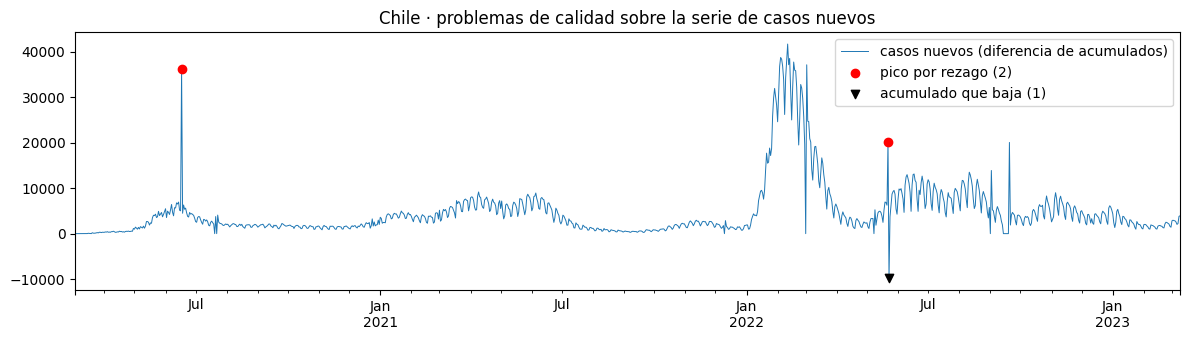

In [11]:
# Chile: detalle de sus problemas
chile = p[p['pais'] == 'Chile'].set_index('fecha_reporte')
print(problemas.loc['Chile'])
fig, ax = plt.subplots(figsize=(12, 3.5))
chile['casos_nuevos'].plot(ax=ax, lw=.7, label='casos nuevos (diferencia de acumulados)')
pk = chile[chile['pico_rezago']]; neg = chile[chile['casos_nuevos'] < 0]
ax.scatter(pk.index, pk['casos_nuevos'].astype(float), color='red', zorder=3, label=f'pico por rezago ({len(pk)})')
ax.scatter(neg.index, neg['casos_nuevos'].astype(float), color='black', marker='v', zorder=3, label=f'acumulado que baja ({len(neg)})')
ax.set_title('Chile · problemas de calidad sobre la serie de casos nuevos'); ax.legend(); ax.set_xlabel('')
plt.tight_layout(); plt.show()

**Lectura de los resultados (primera carga):**
* **Unicidad falla**: hay filas repetidas en la llave territorio × día (y algunas idénticas). Se corrigen dejando una sola fila antes de cargar el DW.
* **Un solo archivo defectuoso explica casi toda la diferencia con el enunciado.** Contando sobre los reportes diarios, 158 países tienen algún día con acumulado que baja; sobre las series de tiempo de JHU son 84 (la cifra del enunciado). La diferencia se concentra en **el reporte del 23-may-2022**, donde el acumulado baja en 136 países a la vez (el archivo trae valores de un corte anterior): sin ese archivo quedan 88 países. Decisión preliminar: **marcar ese archivo** como no confiable y, para los nuevos de ese día y el siguiente, no usar la diferencia simple. Este es un hallazgo que no se ve mirando un solo país.
* **Picos por rezagos**: la regla separa los rezagos reales (Chile el 17-jun-2020: +36 mil casos) del reporte semanal de 2022 (un valor alto cada 7 días es normal en ese régimen y no se marca).
* **Exactitud**: en 65 países la suma de los reportes diarios difiere más de 1 % de la serie de tiempo algún día. En Chile pasa en 106 días, la mayoría antes del cambio a detalle regional (lo revisaremos con el linaje).
* **Fallecidos > casos** aparece en 3 países. El caso extremo es **Corea del Norte**: 300 días informando 1 caso y 6 fallecidos, un dato imposible que muestra por qué se necesita un índice de calidad por país. Esos días se excluyen de la letalidad.
* **K4 (active ≠ confirmed − deaths − recovered)** falla en ~12 % de las filas porque `recovered` deja de actualizarse en 2021: `active` pierde sentido y no se usará en el análisis.
* **O2 (oportunidad)**: en 2022, casi la mitad de los días país no tiene casos nuevos: muchos países pasan a reporte semanal o dejan de informar. Las tendencias de 2022 se calcularán con promedios semanales.

## 6 · Guardar resultados
* `data/clean/homologacion_paises.parquet`: nombre original → país UID → ISO3 (lo usa el DW).
* `data/clean/calidad_reglas.parquet` y `calidad_problemas_pais.parquet`: estado de cada regla y problemas por país en esta carga.

In [12]:
reporte.assign(fecha_evaluacion=pd.Timestamp.now()).to_parquet(CLEAN / 'calidad_reglas.parquet', index=False)
problemas.reset_index().to_parquet(CLEAN / 'calidad_problemas_pais.parquet', index=False)
print('Guardado en', CLEAN)

Guardado en /home/claude/facuna-m/proyecto-gestion-datos-2026/data/clean


## 7 · Decisiones preliminares (a confirmar en la versión final de R2)
| Problema | Decisión preliminar | Por qué |
|---|---|---|
| Nombres de país distintos | **Corregir** con la tabla de homologación (sección 2) | Es el mismo país; no se altera ningún conteo |
| Duplicados en la llave | **Corregir**: conservar la última fila del archivo (la más reciente) | Son repeticiones del mismo reporte |
| Acumulado que baja | **Marcar** (nuevos negativos se conservan y se marcan); no se recalcula la historia | Recalcular sería *inventar* cómo se distribuyó la corrección |
| Picos por rezagos | **Marcar** y mostrar la media móvil de 7 días con advertencia | El total acumulado es correcto; solo su distribución en el tiempo no |
| Fallecidos > casos | **Excluir** de las tasas de letalidad ese día | Es imposible: error de captura |
| Días sin reporte (reporte semanal 2022) | **Marcar**; no imputar ceros ni interpolar | Imputar es inventar; se usan promedios semanales |
| Entidades especiales (cruceros, JJ.OO., Antártica) | **Excluir** de rankings y tasas; conservar en la capa limpia | No tienen población comparable |